# **Lab 9 - Morphological Operations**

**Name:** Mohammed Moayed Alquriniy  
**Student ID:** 2240007325

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

imgFile = 'Balls.png'

# **Task 1: Apply morphological operations to a new image**

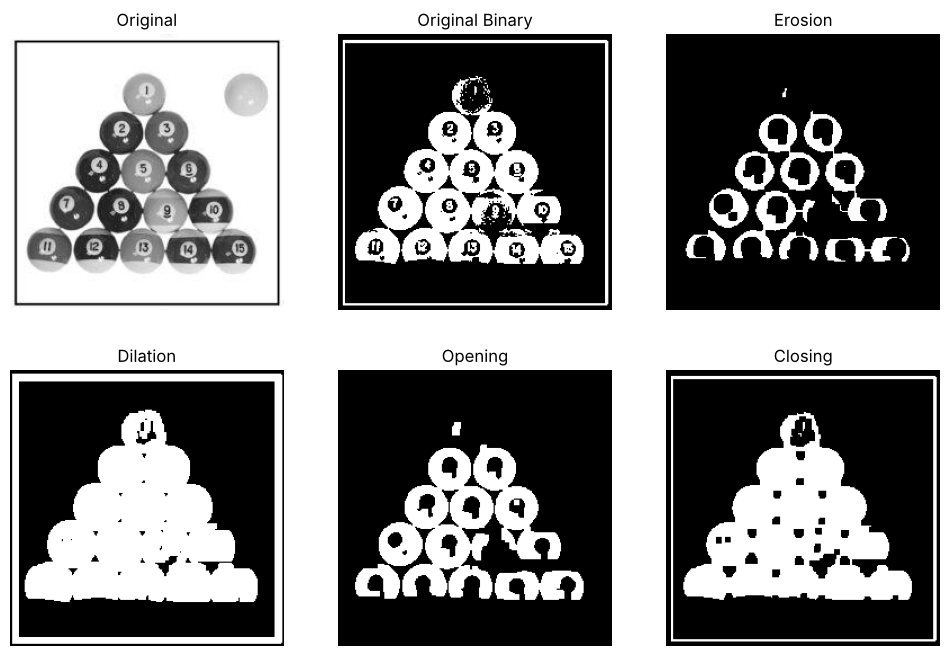

In [2]:
# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Binarize the image (Otsu's method), inverted so the balls (foreground) are white
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# 3. Define a 5x5 kernel
kernel = np.ones((5, 5), np.uint8)

# 4. Apply the morphological operations
erosion  = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening  = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing  = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# 5. Display the original image and the results
titles = ['Original', 'Original Binary', 'Erosion', 'Dilation', 'Opening', 'Closing']
images = [img, binary, erosion, dilation, opening, closing]

plt.figure(figsize=(12, 8))
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.axis('off')
plt.show()

# **Task 2: Experiment with structuring elements**

In [3]:
# 1. Load and binarize the image
img = cv2.imread(imgFile, 0)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# 2. Structuring element shapes and kernel sizes
shapes = {'Square': cv2.MORPH_RECT, 'Cross': cv2.MORPH_CROSS, 'Ellipse': cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]

# 3. Print the structuring elements
for name, shape in shapes.items():
    for s in sizes:
        print(f'{name} {s}x{s}:')
        print(cv2.getStructuringElement(shape, (s, s)))
        print()

Square 3x3:
[[1 1 1]
 [1 1 1]
 [1 1 1]]

Square 5x5:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

Square 7x7:
[[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]

Cross 3x3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]

Cross 5x5:
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]

Cross 7x7:
[[0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [1 1 1 1 1 1 1]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]]

Ellipse 3x3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]

Ellipse 5x5:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]

Ellipse 7x7:
[[0 0 0 1 0 0 0]
 [0 1 1 1 1 1 0]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [0 1 1 1 1 1 0]
 [0 0 0 1 0 0 0]]



## **Erosion with different structuring elements**

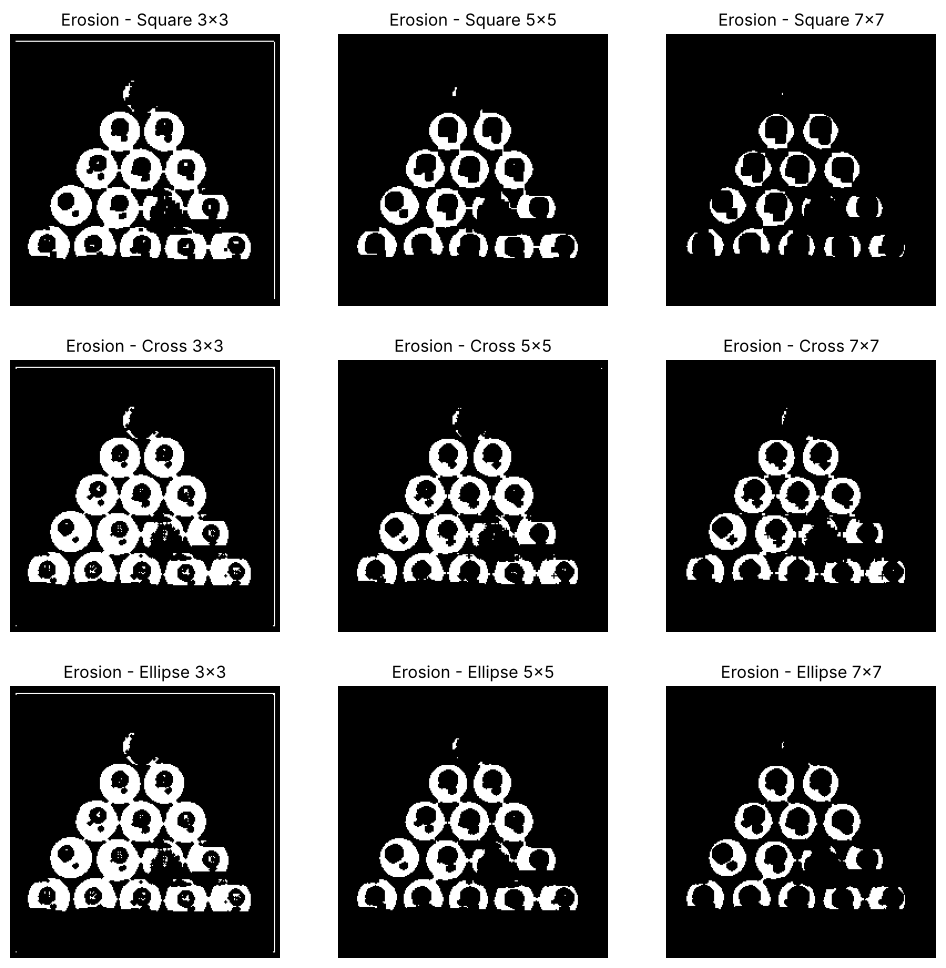

In [4]:
plt.figure(figsize=(12, 12))
i = 1
for name, shape in shapes.items():
    for s in sizes:
        kernel = cv2.getStructuringElement(shape, (s, s))
        eroded = cv2.erode(binary, kernel, iterations=1)
        plt.subplot(3, 3, i)
        plt.imshow(eroded, 'gray')
        plt.title(f'Erosion - {name} {s}x{s}')
        plt.axis('off')
        i += 1
plt.show()

## **Dilation with different structuring elements**

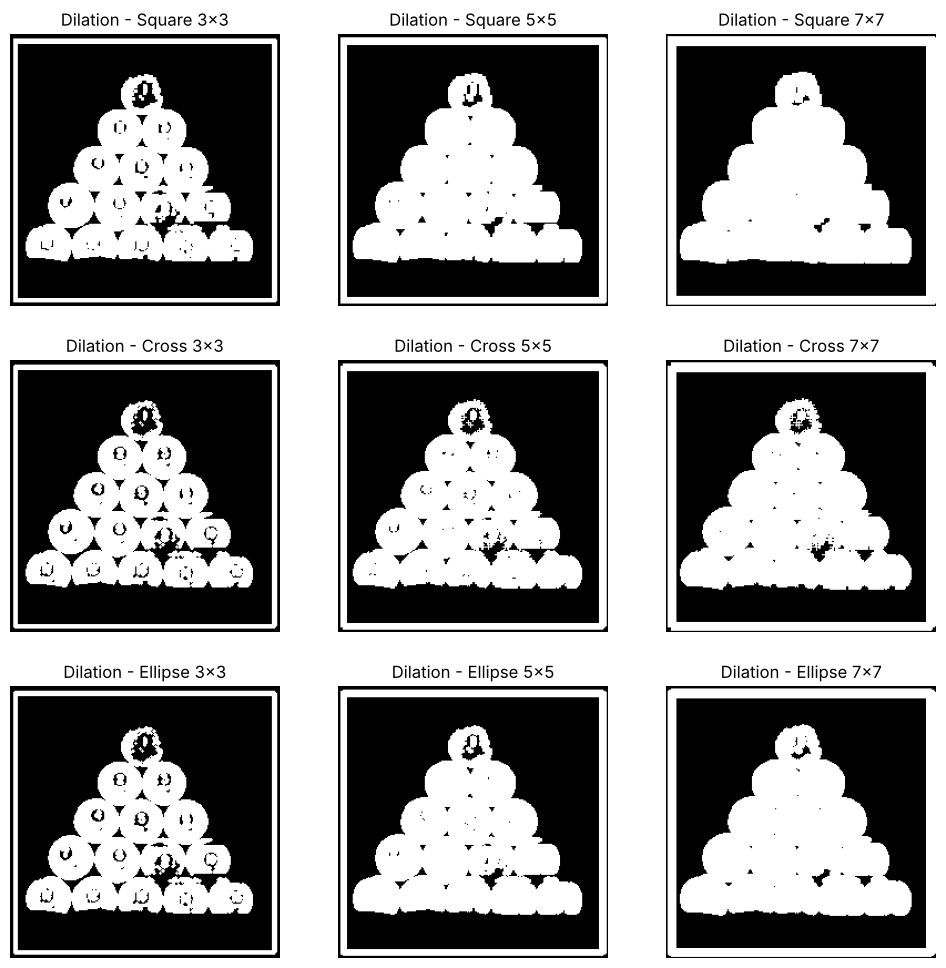

In [5]:
plt.figure(figsize=(12, 12))
i = 1
for name, shape in shapes.items():
    for s in sizes:
        kernel = cv2.getStructuringElement(shape, (s, s))
        dilated = cv2.dilate(binary, kernel, iterations=1)
        plt.subplot(3, 3, i)
        plt.imshow(dilated, 'gray')
        plt.title(f'Dilation - {name} {s}x{s}')
        plt.axis('off')
        i += 1
plt.show()

## **Comparison**

- **Kernel size:** As the kernel size increases (3×3 → 5×5 → 7×7), the effect becomes stronger. Erosion shrinks the balls more and removes small details, while dilation expands the balls more and fills the holes made by the numbers until neighboring balls merge together.
- **Square:** Gives the strongest effect because it covers all pixels in the neighborhood, so edges become more blocky.
- **Cross:** Gives the weakest effect because it only covers horizontal and vertical neighbors, so diagonal details are preserved better.
- **Ellipse:** Gives a result between the square and the cross and keeps the round shape of the balls smoother and more natural.